In [108]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder

In [109]:
df = pd.read_csv("returns_sustainability_dataset.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (5000, 27)


,order_id,product_id,user_id,order_date,product_category,product_price,order_quantity,discount_applied,shipping_method,payment_method,...,return_cost,profit_loss,co2_emissions,packaging_waste,co2_saved,waste_avoided,returned,order_month,order_year,discount_bin
0,ORD00000,PROD0169,USER0195,2022-01-14,Clothing,1720.71,2,30.46,Next-Day,Wallet,...,0,2393.163468,2.0,0.4,2.0,0.4,False,2022-01,2022,"(25.02, 37.38]"
1,ORD00001,PROD0318,USER1469,2022-01-03,Toys,744.06,5,29.62,Next-Day,Wallet,...,200,2418.347140,2.0,1.0,0.0,0.0,True,2022-01,2022,"(25.02, 37.38]"
2,ORD00002,PROD0427,USER1812,2025-03-16,Clothing,983.68,5,47.80,Express,Wallet,...,0,2567.404800,1.5,1.0,1.5,1.0,False,2025-03,2025,"(37.38, 50.0]"
3,ORD00003,PROD0323,USER1274,2024-11-06,Books,1855.65,2,2.90,Express,COD,...,0,3603.672300,1.5,0.4,1.5,0.4,False,2024-11,2024,"(-0.001, 12.828]"
4,ORD00004,PROD0325,USER0551,2023-06-07,Home Appliances,1770.97,5,44.42,Express,COD,...,200,4721.525630,1.5,1.0,0.0,0.0,True,2023-06,2023,"(37.38, 50.0]"


In [110]:
print(df.columns)

Index(['order_id', 'product_id', 'user_id', 'order_date', 'product_category',
       'product_price', 'order_quantity', 'discount_applied',
       'shipping_method', 'payment_method', 'user_age', 'user_gender',
       'user_location', 'return_status', 'return_reason', 'days_to_return',
       'order_value', 'return_cost', 'profit_loss', 'co2_emissions',
       'packaging_waste', 'co2_saved', 'waste_avoided', 'returned',
       'order_month', 'order_year', 'discount_bin'],
      dtype='object')


In [111]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 27 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5000 non-null   object 
 1   product_id        5000 non-null   object 
 2   user_id           5000 non-null   object 
 3   order_date        5000 non-null   object 
 4   product_category  5000 non-null   object 
 5   product_price     5000 non-null   float64
 6   order_quantity    5000 non-null   int64  
 7   discount_applied  5000 non-null   float64
 8   shipping_method   5000 non-null   object 
 9   payment_method    5000 non-null   object 
 10  user_age          5000 non-null   int64  
 11  user_gender       5000 non-null   object 
 12  user_location     5000 non-null   object 
 13  return_status     5000 non-null   object 
 14  return_reason     5000 non-null   object 
 15  days_to_return    5000 non-null   int64  
 16  order_value       5000 non-null   float64


In [112]:
df.describe()

,product_price,order_quantity,discount_applied,user_age,days_to_return,order_value,return_cost,profit_loss,co2_emissions,packaging_waste,co2_saved,waste_avoided,order_year
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000
mean,1054.294740,2.997600,25.011476,41.551800,9.204200,2366.996469,58.000000,2308.996469,1.500100,0.599520,1.066600,0.42668,2023.378600
std,548.560406,1.400709,14.430681,13.890195,16.753156,1834.851991,90.761487,1838.461511,0.410346,0.280142,0.764448,0.36150,1.077355
min,100.090000,1.000000,0.000000,18.000000,0.000000,52.165727,0.000000,-147.834273,1.000000,0.200000,0.000000,0.00000,2022.000000
25%,580.937500,2.000000,12.827500,30.000000,0.000000,928.078449,0.000000,863.905130,1.000000,0.400000,0.000000,0.00000,2022.000000
50%,1044.850000,3.000000,25.020000,42.000000,0.000000,1864.584054,0.000000,1808.077845,1.500000,0.600000,1.000000,0.40000,2023.000000
75%,1530.835000,4.000000,37.380000,54.000000,12.000000,3382.309799,200.000000,3345.675860,2.000000,0.800000,1.500000,0.80000,2024.000000
max,1999.800000,5.000000,50.000000,65.000000,60.000000,9827.017200,200.000000,9827.017200,2.000000,1.000000,2.000000,1.00000,2025.000000


In [113]:
df.describe(include='object')


,order_id,product_id,user_id,order_date,product_category,shipping_method,payment_method,user_gender,user_location,return_status,return_reason,order_month,discount_bin
count,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000
unique,5000,500,1858,1309,5,3,4,2,100,2,5,45,4
top,ORD04999,PROD0176,USER1886,2022-04-04,Clothing,Next-Day,Debit Card,Female,City35,Not Returned,No Return,2024-12,"(25.02, 37.38]"
freq,1,22,9,11,1766,1684,1277,2576,72,3550,3550,140,1251


In [114]:
missing_values = df.isnull().sum()

print(missing_values)

order_id            0
product_id          0
user_id             0
order_date          0
product_category    0
product_price       0
order_quantity      0
discount_applied    0
shipping_method     0
payment_method      0
user_age            0
user_gender         0
user_location       0
return_status       0
return_reason       0
days_to_return      0
order_value         0
return_cost         0
profit_loss         0
co2_emissions       0
packaging_waste     0
co2_saved           0
waste_avoided       0
returned            0
order_month         0
order_year          0
discount_bin        0
dtype: int64


In [115]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [116]:
# Leakage check: these columns exist only AFTER an order is returned
print(pd.crosstab(df["return_status"], df["returned"]))
print()
print(pd.crosstab(df["return_reason"], df["returned"]))

returned       False  True 
return_status              
Not Returned    3550      0
Returned           0   1450

returned       False  True 
return_reason              
Changed Mind       0    379
Defective          0    382
No Return       3550      0
Size Issue         0    341
Wrong Item         0    348


In [117]:
print("profit_loss = order_value - return_cost:",
      np.allclose(df["profit_loss"], df["order_value"] - df["return_cost"]))

not_returned = df[df["returned"] == False]
print("co2_saved = co2_emissions when not returned:",
      np.allclose(not_returned["co2_saved"], not_returned["co2_emissions"]))

profit_loss = order_value - return_cost: True
co2_saved = co2_emissions when not returned: True


In [118]:
print("order_value = price x quantity x (1 - discount/100):",
      np.allclose(df["order_value"],
                  df["product_price"] * df["order_quantity"] * (1 - df["discount_applied"] / 100)))

print("packaging_waste = 0.2 x order_quantity:",
      np.allclose(df["packaging_waste"], 0.2 * df["order_quantity"]))

print()
print(df.groupby("shipping_method")["co2_emissions"].unique())

order_value = price x quantity x (1 - discount/100): True
packaging_waste = 0.2 x order_quantity: True

shipping_method
Express     [1.5]
Next-Day    [2.0]
Standard    [1.0]
Name: co2_emissions, dtype: object


In [119]:
print(df.groupby("returned")[["days_to_return", "return_cost"]].agg(["min", "max"]))
print()
print(df.groupby("returned")[["co2_saved", "waste_avoided"]].agg(["min", "max"]))

         days_to_return     return_cost     
                    min max         min  max
returned                                    
False                 0   0           0    0
True                  5  60         200  200

         co2_saved      waste_avoided     
               min  max           min  max
returned                                  
False          1.0  2.0           0.2  1.0
True           0.0  0.0           0.0  0.0


In [120]:
categorical_columns = df.select_dtypes(include='object').columns

for column in categorical_columns:
    print("\n", column)
    print(df[column].value_counts())


 order_id
order_id
ORD04999    1
ORD00000    1
ORD00001    1
ORD00002    1
ORD00003    1
           ..
ORD00012    1
ORD00011    1
ORD00010    1
ORD00009    1
ORD00008    1
Name: count, Length: 5000, dtype: int64

 product_id
product_id
PROD0176    22
PROD0002    21
PROD0370    19
PROD0476    19
PROD0062    19
            ..
PROD0303     4
PROD0205     4
PROD0127     4
PROD0038     3
PROD0363     3
Name: count, Length: 500, dtype: int64

 user_id
user_id
USER1886    9
USER1562    9
USER0780    9
USER0081    8
USER0220    8
           ..
USER0194    1
USER1255    1
USER1117    1
USER0055    1
USER0366    1
Name: count, Length: 1858, dtype: int64

 order_date
order_date
2022-04-04    11
2024-12-24    11
2024-02-03    11
2023-01-19    11
2022-04-22    10
              ..
2022-11-19     1
2022-11-27     1
2023-07-22     1
2022-09-03     1
2025-06-04     1
Name: count, Length: 1309, dtype: int64

 product_category
product_category
Clothing           1766
Electronics        1244
Books      

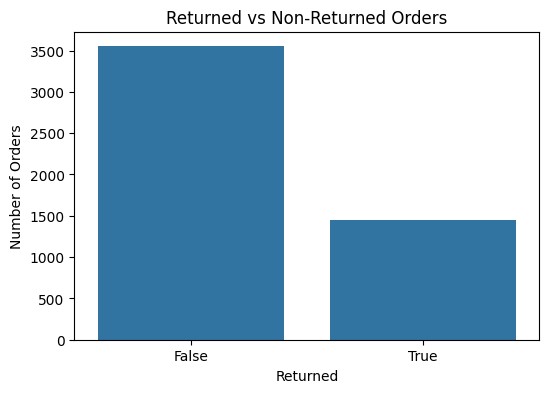

In [121]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='returned')

plt.title("Returned vs Non-Returned Orders")
plt.xlabel("Returned")
plt.ylabel("Number of Orders")

plt.show()

In [122]:
return_percentage = df['returned'].value_counts(normalize=True) * 100

print(return_percentage)

returned
False    71.0
True     29.0
Name: proportion, dtype: float64


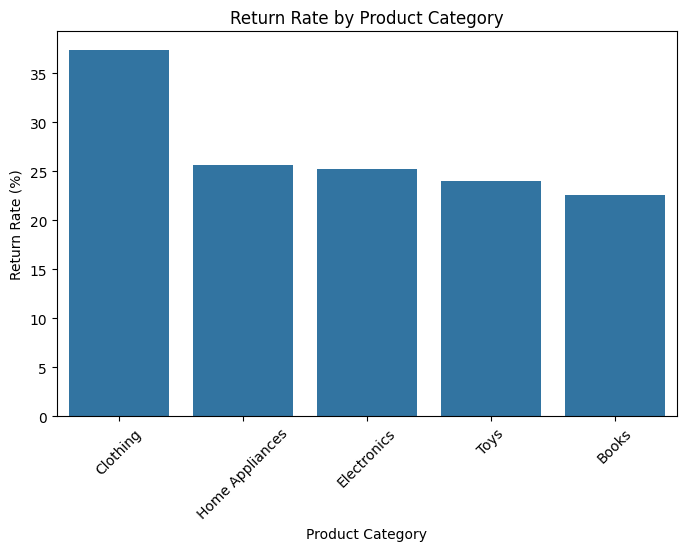

In [123]:
return_rate_category = (
    df.groupby('product_category')['returned']
      .mean()
      .sort_values(ascending=False) * 100
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=return_rate_category.index,
    y=return_rate_category.values
)

plt.title("Return Rate by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Return Rate (%)")
plt.xticks(rotation=45)

plt.show()

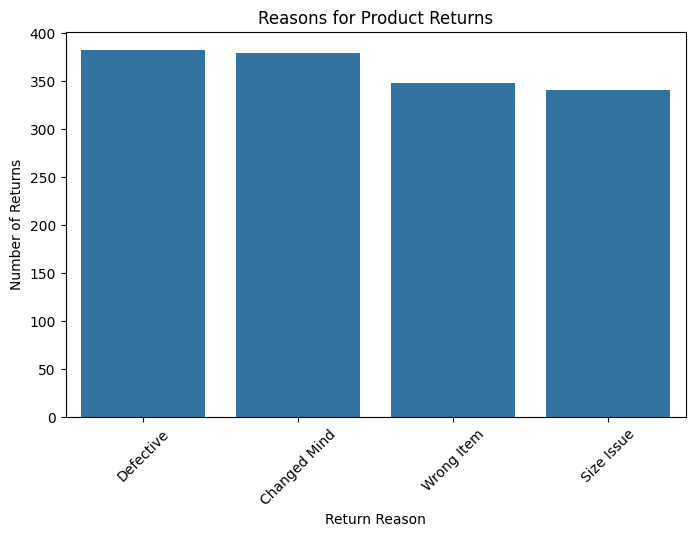

In [124]:
returned_orders = df[df['returned'] == True]

reason_counts = returned_orders['return_reason'].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=reason_counts.index,
    y=reason_counts.values
)

plt.title("Reasons for Product Returns")
plt.xlabel("Return Reason")
plt.ylabel("Number of Returns")
plt.xticks(rotation=45)

plt.show()

In [125]:
reason_percentage = returned_orders['return_reason'].value_counts(normalize=True) * 100

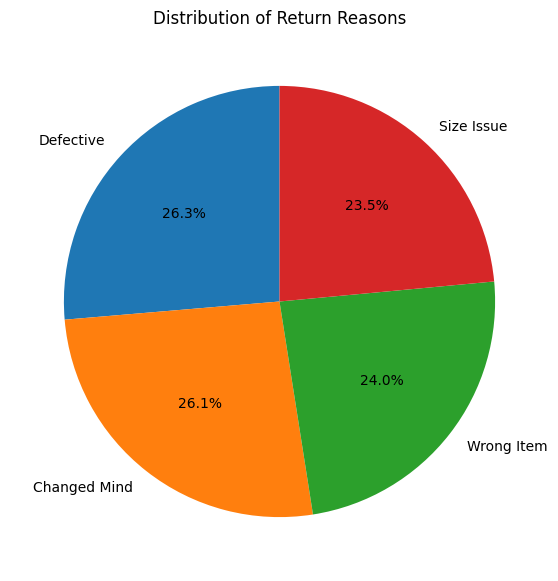

In [126]:
plt.figure(figsize=(7, 7))

plt.pie(
    reason_percentage.values,
    labels=reason_percentage.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Distribution of Return Reasons")

plt.show()

In [127]:
category_return = pd.crosstab(
    df['product_category'],
    df['returned'],
    normalize='index'
) * 100

print(category_return)

returned              False      True 
product_category                      
Books             77.427822  22.572178
Clothing          62.570781  37.429219
Electronics       74.758842  25.241158
Home Appliances   74.369748  25.630252
Toys              75.930851  24.069149


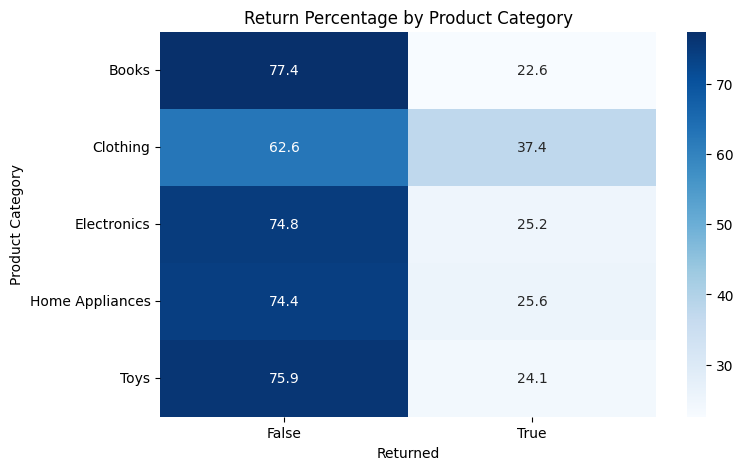

In [128]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    category_return,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title("Return Percentage by Product Category")
plt.xlabel("Returned")
plt.ylabel("Product Category")

plt.show()

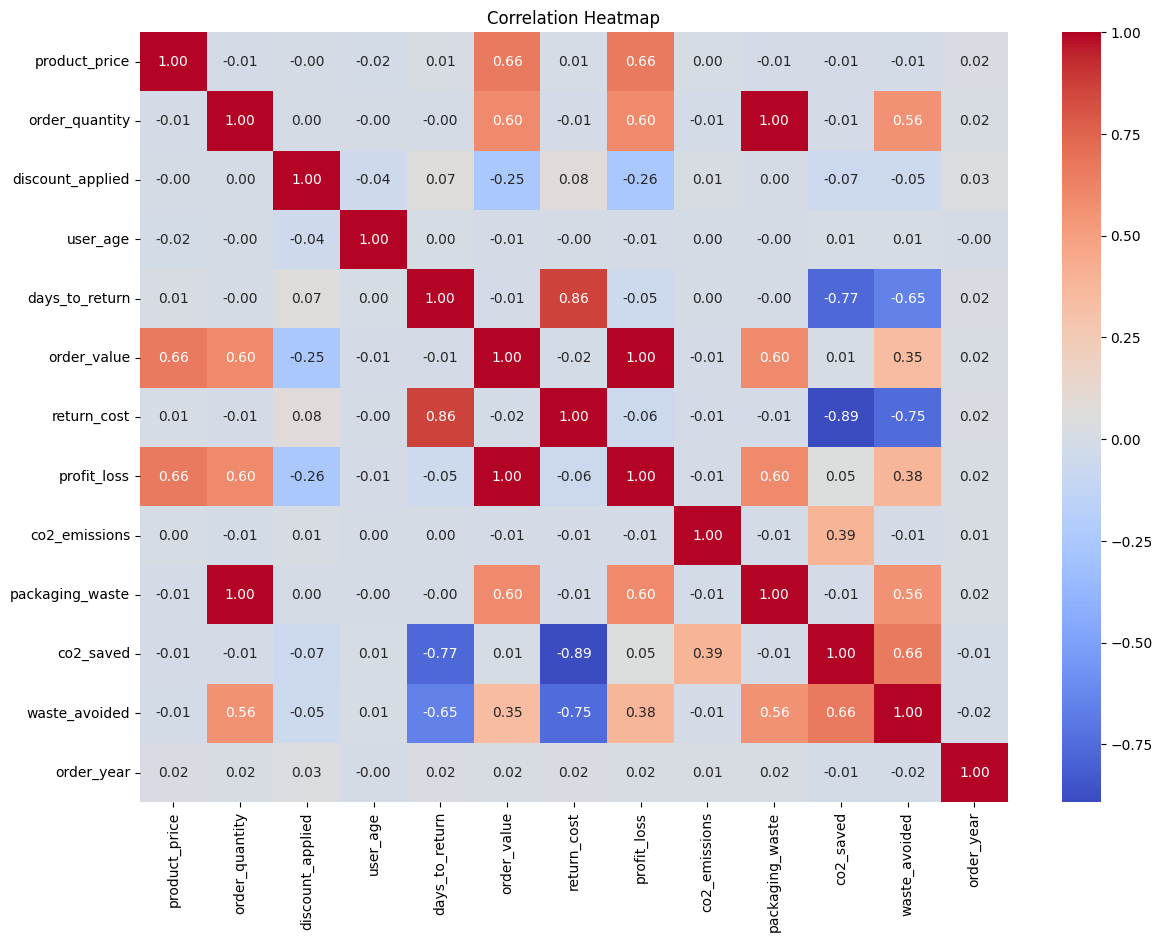

In [129]:
numeric_columns = df.select_dtypes(include=np.number).columns

plt.figure(figsize=(14, 10))

correlation = df[numeric_columns].corr()

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

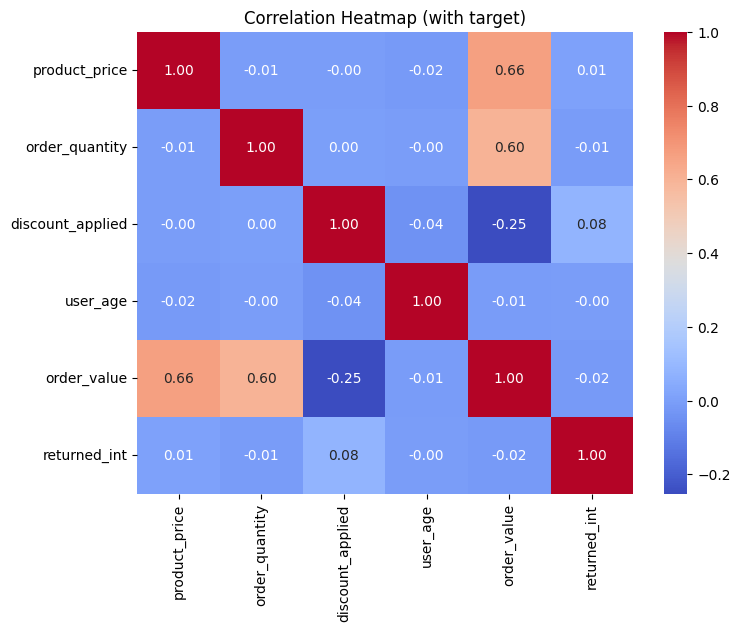

In [130]:
df["returned_int"] = df["returned"].astype(int)

corr_columns = ['product_price', 'order_quantity', 'discount_applied',
                'user_age', 'order_value', 'returned_int']

plt.figure(figsize=(8, 6))
sns.heatmap(df[corr_columns].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap (with target)")
plt.show()

In [131]:
numeric_columns = df.select_dtypes(include=np.number).columns

print(numeric_columns)

Index(['product_price', 'order_quantity', 'discount_applied', 'user_age',
       'days_to_return', 'order_value', 'return_cost', 'profit_loss',
       'co2_emissions', 'packaging_waste', 'co2_saved', 'waste_avoided',
       'order_year', 'returned_int'],
      dtype='object')


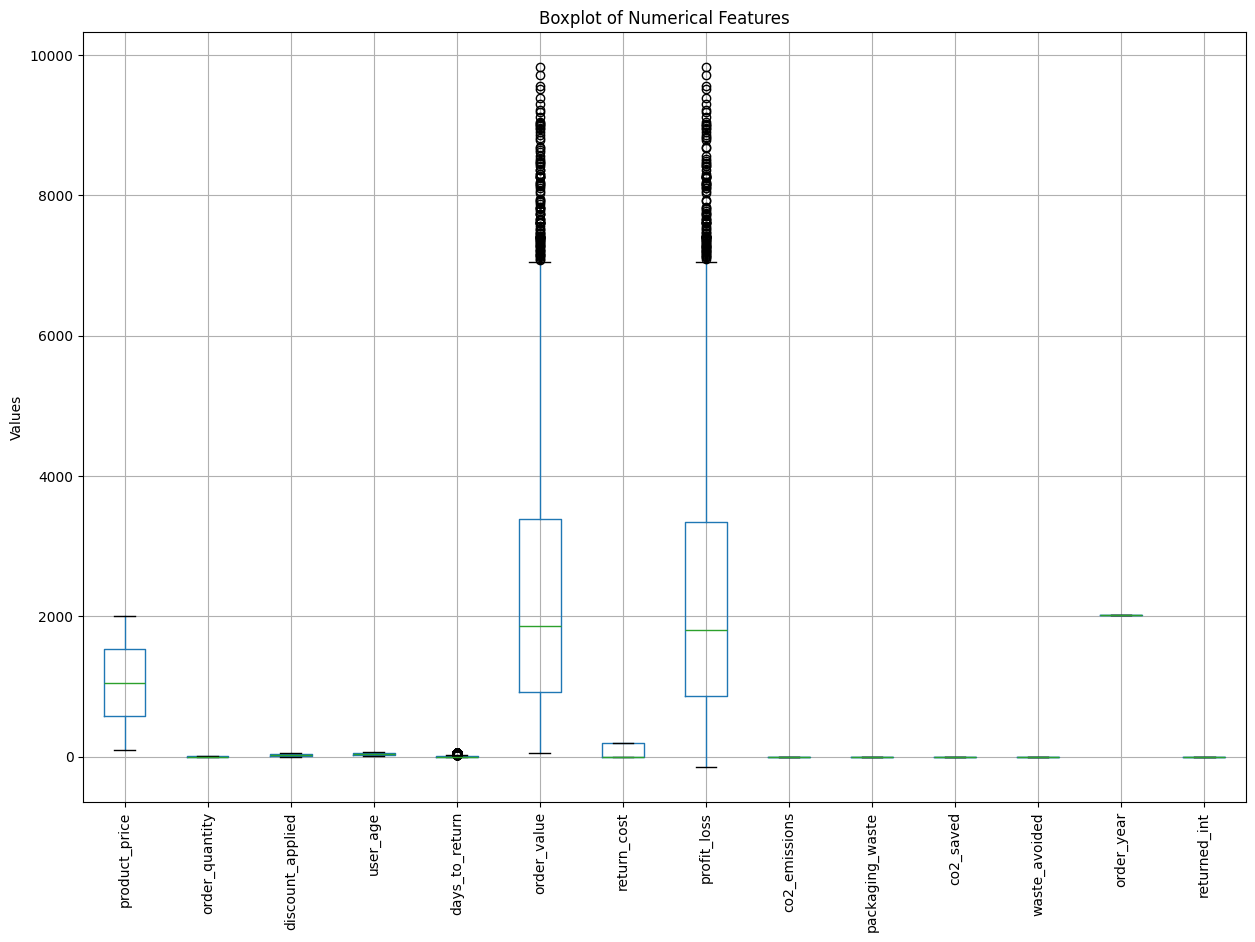

In [132]:
plt.figure(figsize=(15, 10))

df[numeric_columns].boxplot()

plt.xticks(rotation=90)
plt.title("Boxplot of Numerical Features")
plt.ylabel("Values")

plt.show()

In [133]:
def detect_outliers_iqr(data, column):

    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    print("Column:", column)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))

    return outliers

In [134]:
detect_outliers_iqr(df, 'product_price')

Column: product_price
Q1: 580.9375
Q3: 1530.835
IQR: 949.8975
Lower Bound: -843.90875
Upper Bound: 2955.68125
Number of Outliers: 0


,order_id,product_id,user_id,order_date,product_category,product_price,order_quantity,discount_applied,shipping_method,payment_method,...,profit_loss,co2_emissions,packaging_waste,co2_saved,waste_avoided,returned,order_month,order_year,discount_bin,returned_int


In [135]:
for column in [
    'product_price',
    'order_quantity',
    'discount_applied',
    'user_age',
    'order_value'
]:
    detect_outliers_iqr(df, column)

Column: product_price
Q1: 580.9375
Q3: 1530.835
IQR: 949.8975
Lower Bound: -843.90875
Upper Bound: 2955.68125
Number of Outliers: 0
Column: order_quantity
Q1: 2.0
Q3: 4.0
IQR: 2.0
Lower Bound: -1.0
Upper Bound: 7.0
Number of Outliers: 0
Column: discount_applied
Q1: 12.8275
Q3: 37.38
IQR: 24.552500000000002
Lower Bound: -24.00125
Upper Bound: 74.20875000000001
Number of Outliers: 0
Column: user_age
Q1: 30.0
Q3: 54.0
IQR: 24.0
Lower Bound: -6.0
Upper Bound: 90.0
Number of Outliers: 0
Column: order_value
Q1: 928.078449
Q3: 3382.309799
IQR: 2454.23135
Lower Bound: -2753.268576
Upper Bound: 7063.656824
Number of Outliers: 108


In [136]:
def remove_outliers_iqr(data, column):

    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    data = data[
        (data[column] >= lower_bound) &
        (data[column] <= upper_bound)
    ]

    return data

In [137]:
df_clean = remove_outliers_iqr(df, 'product_price')

print("Original shape:", df.shape)
print("After outlier removal:", df_clean.shape)

Original shape: (5000, 28)
After outlier removal: (5000, 28)


In [138]:
df["order_month_num"] = pd.to_datetime(df["order_month"], format="%Y-%m").dt.month

In [139]:
features = [
    'product_category',
    'product_price',
    'order_quantity',
    'discount_applied',
    'shipping_method',
    'payment_method',
    'user_age',
    'user_gender',
    'order_value',
    'order_month_num'
]

In [140]:
leakage_cols = ["return_status", "return_reason", "days_to_return",
                "return_cost", "profit_loss", "co2_saved", "waste_avoided"]
redundant_cols = ["co2_emissions", "packaging_waste", "discount_bin"]

print("Leaky columns in features:", [c for c in features if c in leakage_cols])
print("Redundant columns in features:", [c for c in features if c in redundant_cols])

Leaky columns in features: []
Redundant columns in features: []


In [141]:
target = 'returned'

In [142]:
X = df[features].copy()

y = df['returned'].astype(int)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (5000, 10)
y shape: (5000,)


In [143]:
from sklearn.preprocessing import OneHotEncoder

In [144]:
categorical_features = [
    'product_category',
    'shipping_method',
    'payment_method',
    'user_gender'
]

numerical_features = [
    'product_price',
    'order_quantity',
    'discount_applied',
    'user_age',
    'order_value',
    'order_month_num'
]

In [145]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [146]:
preprocessor = ColumnTransformer(
    transformers=[

        ('num',
         StandardScaler(),
         numerical_features),

        ('cat',
         OneHotEncoder(handle_unknown='ignore'),
         categorical_features)
    ]
)

In [148]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4000, 10)
Testing data: (1000, 10)


In [149]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [150]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            StandardScaler(),
            numerical_features
        ),
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        )
    ]
)

In [151]:
# Fit ONLY on training data, then apply to test data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Train processed shape:", X_train_processed.shape)
print("Test processed shape:", X_test_processed.shape)

Train processed shape: (4000, 20)
Test processed shape: (1000, 20)


In [152]:
import joblib

feature_names = preprocessor.get_feature_names_out()

joblib.dump(
    {
        "X_train": X_train_processed,
        "X_test": X_test_processed,
        "y_train": y_train.to_numpy(),
        "y_test": y_test.to_numpy(),
        "feature_names": list(feature_names),
        "preprocessor": preprocessor
    },
    "processed_data.joblib"
)
print("Saved processed_data.joblib")

Saved processed_data.joblib
